Reading and Understanding the Dataset


In [ ]:
# Import libraries for data manipulation
import pandas as pd
import numpy as np 

# Import libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import preprocessing and machine learning libraries
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
import joblib
from xgboost import XGBRegressor


df = pd.read_csv(r"datasets\cardekho.csv")
df.sample(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
1584,Maruti Baleno Delta 1.2,2018,575000,20000,Petrol,Individual,Manual,First Owner,21.40,1197.0,83.1,5.0
6505,Mahindra Scorpio 1.99 S6 Plus,2015,800000,70000,Diesel,Individual,Manual,First Owner,15.40,1997.0,120,7.0
4900,Ford Endeavour 2.5L 4X2 MT,2004,400000,93415,Diesel,Dealer,Manual,First Owner,13.10,2499.0,141,7.0
3167,Tata Manza Aura Safire,2011,225000,35000,Petrol,Individual,Manual,First Owner,15.00,1368.0,90,5.0
6527,Hyundai i20 Asta 1.4 CRDi,2013,380000,110000,Diesel,Individual,Manual,Second Owner,21.27,1396.0,88.76,5.0


In [4]:
df.shape

(8128, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8128 non-null   object 
 1   year                8128 non-null   int64  
 2   selling_price       8128 non-null   int64  
 3   km_driven           8128 non-null   int64  
 4   fuel                8128 non-null   object 
 5   seller_type         8128 non-null   object 
 6   transmission        8128 non-null   object 
 7   owner               8128 non-null   object 
 8   mileage(km/ltr/kg)  7907 non-null   float64
 9   engine              7907 non-null   float64
 10  max_power           7913 non-null   object 
 11  seats               7907 non-null   float64
dtypes: float64(3), int64(3), object(6)
memory usage: 762.1+ KB


In [6]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage(km/ltr/kg)', 'engine', 'max_power',
       'seats'],
      dtype='object')

In [7]:
#numerical stats
df.describe()

,year,selling_price,km_driven,mileage(km/ltr/kg),engine,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000,7907.000000,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,19.418783,1458.625016,5.416719
std,4.044249,8.062534e+05,5.655055e+04,4.037145,503.916303,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,16.780000,1197.000000,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,19.300000,1248.000000,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,22.320000,1582.000000,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,14.000000


In [8]:
#missing values
df.isna().sum()

name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    221
engine                221
max_power             215
seats                 221
dtype: int64

In [9]:
# Missing Value filled 
mileage_mean = df['mileage(km/ltr/kg)'].mean()

df['mileage(km/ltr/kg)'] = df['mileage(km/ltr/kg)'].fillna(mileage_mean,inplace=False)

df['engine'] = df['engine'].fillna(0,inplace=False)

df['max_power'] = df['max_power'].astype(str).str.extract(r'([\d\.]+)').astype(float)
max_power_mean = df['max_power'].mean()

df['max_power'] = df['max_power'].fillna(max_power_mean)

seats_mean = df['seats'].mean()
df['seats'] = df['seats'].fillna(seats_mean,inplace=False)


In [10]:
seller_type = df.groupby('seller_type')['year'].count()
seller_type

seller_type
Dealer              1126
Individual          6766
Trustmark Dealer     236
Name: year, dtype: int64

In [11]:
df['age'] = 2026 - df['year']

In [12]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage(km/ltr/kg)', 'engine', 'max_power',
       'seats', 'age'],
      dtype='object')

In [13]:
# Find the average selling price for each fuel type.
avg_selling_price = df.groupby('fuel')['selling_price'].mean().reset_index(name="average selling price")
print(" The average selling price for each fuel type are:")
avg_selling_price

 The average selling price for each fuel type are:


,fuel,average selling price
0,CNG,301017.491228
1,Diesel,791452.921627
2,LPG,200421.052632
3,Petrol,462441.061691


In [14]:
# Find the median selling price for each fuel type.
median_selling_price = df.groupby('fuel')['selling_price'].median().reset_index(name="median selling price")
print(" The median selling price for each fuel type are:")
median_selling_price

 The median selling price for each fuel type are:


,fuel,median selling price
0,CNG,320000.0
1,Diesel,550000.0
2,LPG,195500.0
3,Petrol,345000.0


In [15]:
# Find the average selling price for each seller type.
avg_selling_price = df.groupby('seller_type')['selling_price'].mean().reset_index(name="average selling price")
print(" The average selling price for each seller type are:")
avg_selling_price

 The average selling price for each seller type are:


,seller_type,average selling price
0,Dealer,1.443494e+06
1,Individual,4.985612e+05
2,Trustmark Dealer,8.018390e+05


In [16]:
# Find the average selling price for each transmission type.
transmission_avg_selling_price = df.groupby('transmission')['selling_price'].mean().reset_index(name="average selling price")
print(" The average selling price for each transmission type are:")
transmission_avg_selling_price

 The average selling price for each transmission type are:


,transmission,average selling price
0,Automatic,1.870828e+06
1,Manual,4.554259e+05


In [17]:
# Find the average selling price for each owner category.
category_avg_selling_price = df.groupby('owner')['selling_price'].mean().reset_index(name="average selling price")
print(" The average selling price for each owner category are:")
category_avg_selling_price

 The average selling price for each owner category are:


,owner,average selling price
0,First Owner,7.830864e+05
1,Fourth & Above Owner,2.258132e+05
2,Second Owner,3.929645e+05
3,Test Drive Car,4.403800e+06
4,Third Owner,2.840153e+05


In [18]:
# Find the average `km_driven` for each fuel type.
km_driven_avg = df.groupby('fuel')['km_driven'].mean().reset_index(name="average km driven")
print(" The average `km_driven` for each fuel type are:")
km_driven_avg

 The average `km_driven` for each fuel type are:


,fuel,average km driven
0,CNG,68288.438596
1,Diesel,83677.137210
2,LPG,89174.105263
3,Petrol,52840.861746


In [19]:
# Find the average selling price for each combination of `fuel` and `transmission`.
fuel_transmission_avg_selling_price = df.groupby(['fuel','transmission'])['selling_price'].mean().reset_index(name="average selling price")
print(" The average selling price for each combination of `fuel` and `transmission` are:")
fuel_transmission_avg_selling_price

 The average selling price for each combination of `fuel` and `transmission` are:


,fuel,transmission,average selling price
0,CNG,Manual,3.010175e+05
1,Diesel,Automatic,2.541693e+06
2,Diesel,Manual,5.498221e+05
3,LPG,Manual,2.004211e+05
4,Petrol,Automatic,1.176560e+06
5,Petrol,Manual,3.441472e+05


In [20]:
# Find the average selling price for each combination of `seller_type` and `transmission`.
seller_type_transmission_avg_selling_price = df.groupby(['seller_type','transmission'])['selling_price'].mean().reset_index(name="average selling price")
print(" The average selling price for each combination of `seller_type` and `transmission` are:")
seller_type_transmission_avg_selling_price

 The average selling price for each combination of `seller_type` and `transmission` are:


,seller_type,transmission,average selling price
0,Dealer,Automatic,2.676083e+06
1,Dealer,Manual,5.952803e+05
2,Individual,Automatic,1.269539e+06
3,Individual,Manual,4.381021e+05
4,Trustmark Dealer,Automatic,1.125596e+06
5,Trustmark Dealer,Manual,5.678832e+05


In [21]:
# Find the average selling price by manufacturing year.
avg_selling_price_manufacturing = df.groupby('year')['selling_price'].mean().reset_index(name="average selling price")
print(" The average selling price by manufacturing year are:")
avg_selling_price_manufacturing


 The average selling price by manufacturing year are:


,year,average selling price
0,1983,3.000000e+05
1,1991,5.500000e+04
2,1994,8.800000e+04
3,1995,1.075000e+05
4,1996,8.166667e+04
5,1997,9.018173e+04
6,1998,7.310000e+04
7,1999,7.583333e+04
8,2000,9.304155e+04
9,2001,4.849830e+04


In [22]:
# Calculate the correlation matrix for numerical variables.
corr_matrix = df.corr(numeric_only=True)
corr_matrix


,year,selling_price,km_driven,mileage(km/ltr/kg),engine,max_power,seats,age
year,1.000000,0.414092,-0.418006,0.310383,0.129553,0.213282,-0.008623,-1.000000
selling_price,0.414092,1.000000,-0.225534,-0.125454,0.445985,0.744958,0.041161,-0.414092
km_driven,-0.418006,-0.225534,1.000000,-0.171426,0.155493,-0.037714,0.225172,0.418006
mileage(km/ltr/kg),0.310383,-0.125454,-0.171426,1.000000,-0.519666,-0.373586,-0.452085,-0.310383
engine,0.129553,0.445985,0.155493,-0.519666,1.000000,0.638729,0.550780,-0.129553
max_power,0.213282,0.744958,-0.037714,-0.373586,0.638729,1.000000,0.191435,-0.213282
seats,-0.008623,0.041161,0.225172,-0.452085,0.550780,0.191435,1.000000,0.008623
age,-1.000000,-0.414092,0.418006,-0.310383,-0.129553,-0.213282,0.008623,1.000000


                   year  selling_price
year           1.000000       0.414092
selling_price  0.414092       1.000000


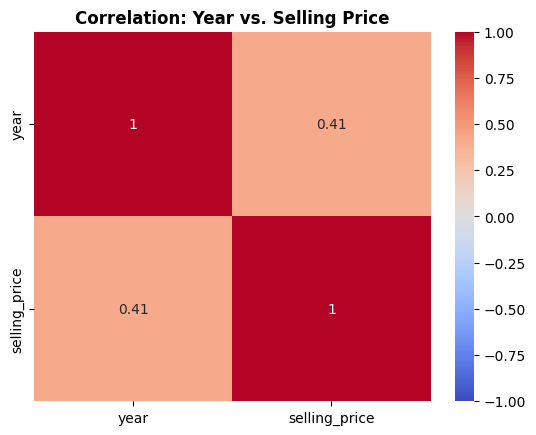

In [23]:
matrix_corr = df[['year', 'selling_price']].corr()
print(matrix_corr)

sns.heatmap(matrix_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation: Year vs. Selling Price",fontweight='bold')
plt.show()


Analyze the correlation between `km_driven` and `selling_price`:
                   year  selling_price
year           1.000000       0.414092
selling_price  0.414092       1.000000


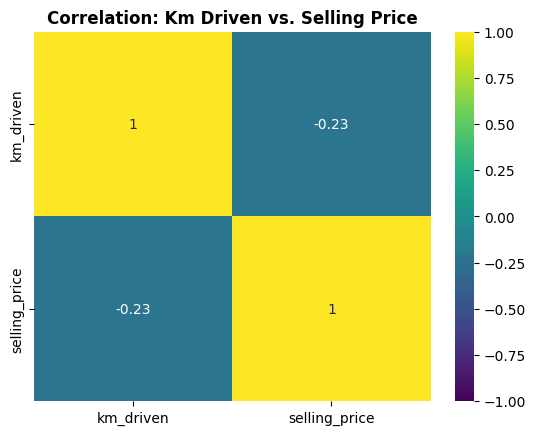

Analyze the correlation between `engine` and `selling_price`:
                 engine  selling_price
engine         1.000000       0.445985
selling_price  0.445985       1.000000


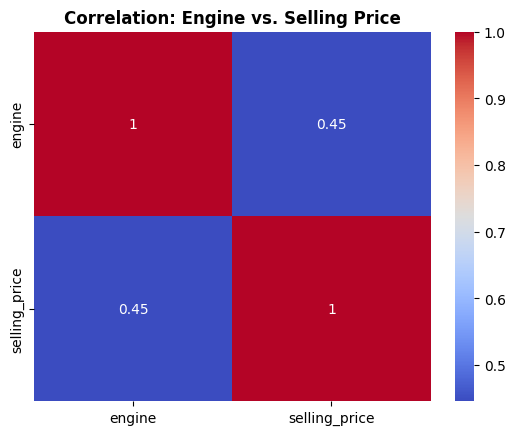

Analyze the correlation between `seats` and `selling_price`:
                  seats  selling_price
seats          1.000000       0.041161
selling_price  0.041161       1.000000


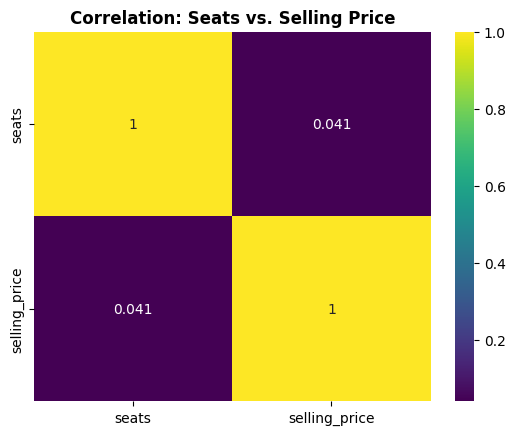

In [24]:
# Analyze the correlation between `km_driven` and `selling_price`.
matrix_km_driven_corr = df[['km_driven', 'selling_price']].corr()
print("Analyze the correlation between `km_driven` and `selling_price`:")
print(matrix_corr)

sns.heatmap(matrix_km_driven_corr, annot=True, cmap="viridis", vmin=-1, vmax=1)
plt.title("Correlation: Km Driven vs. Selling Price",fontweight='bold')
plt.show()

# Analyze the correlation between `engine` and `selling_price`.
matrix_engine_corr = df[['engine', 'selling_price']].corr()
print("Analyze the correlation between `engine` and `selling_price`:")
print(matrix_engine_corr)

sns.heatmap(matrix_engine_corr, annot=True, cmap="coolwarm")
plt.title("Correlation: Engine vs. Selling Price",fontweight='bold')
plt.show()

# Analyze the correlation between `seats` and `selling_price`.
matrix_seats_corr = df[['seats', 'selling_price']].corr()
print("Analyze the correlation between `seats` and `selling_price`:")
print(matrix_seats_corr)

sns.heatmap(matrix_seats_corr, annot=True, cmap="viridis")
plt.title("Correlation: Seats vs. Selling Price",fontweight='bold')
plt.show()

     fuel  no_of_cars
0     CNG          57
1  Diesel        4402
2     LPG          38
3  Petrol        3631


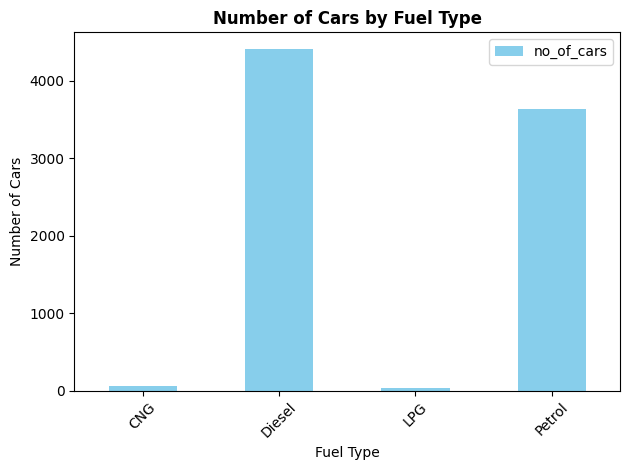

In [25]:
# Create a bar chart showing the number of cars by fuel type.
d = df.groupby('fuel')['year'].count().reset_index(name="no_of_cars")
print(d)

d.plot.bar(x='fuel', y='no_of_cars', color='skyblue')
plt.title('Number of Cars by Fuel Type',fontweight='bold')
plt.ylabel('Number of Cars') 
plt.xlabel('Fuel Type')
plt.xticks(rotation=45)  # Rotates the fuel labels so they don't overlap
plt.tight_layout()   
plt.show()    

     fuel  average_selling_price
0     CNG          301017.491228
1  Diesel          791452.921627
2     LPG          200421.052632
3  Petrol          462441.061691


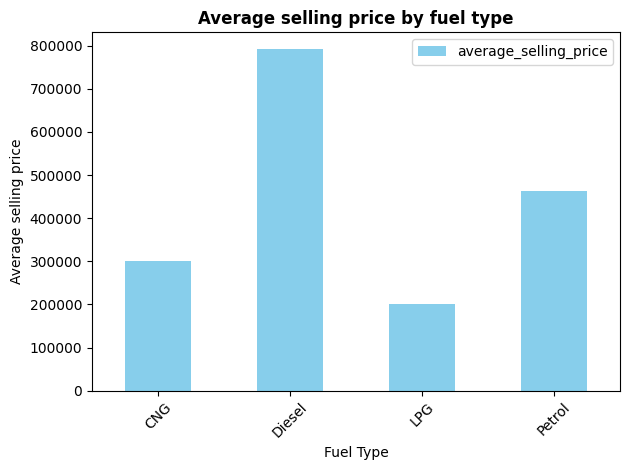

  transmission  average_selling_price
0    Automatic           1.870828e+06
1       Manual           4.554259e+05


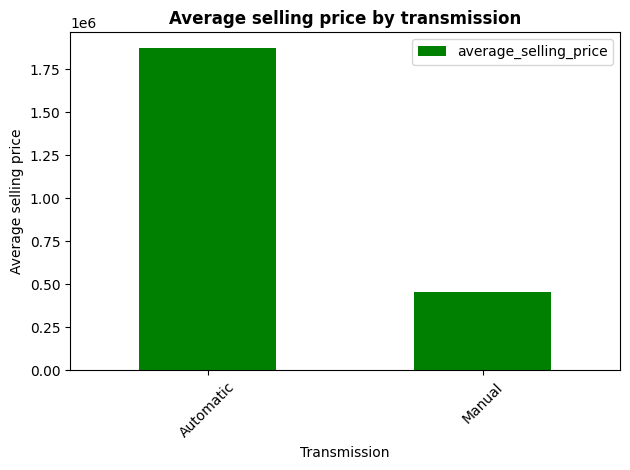

In [26]:
# Create a bar chart showing average selling price by fuel type.
avg_selling_price_fuel_type = df.groupby('fuel')['selling_price'].mean().reset_index(name="average_selling_price")
print(avg_selling_price_fuel_type)

avg_selling_price_fuel_type.plot.bar(x='fuel', y='average_selling_price', color='skyblue')
plt.title('Average selling price by fuel type',fontweight='bold')
plt.ylabel('Average selling price') 
plt.xlabel('Fuel Type')
plt.xticks(rotation=45)  # Rotates the fuel labels so they don't overlap
plt.tight_layout()   
plt.show()    

# Create a bar chart showing average selling price by transmission.
avg_selling_price_transmission = df.groupby('transmission')['selling_price'].mean().reset_index(name="average_selling_price")
print(avg_selling_price_transmission)

avg_selling_price_transmission.plot.bar(x='transmission', y='average_selling_price', color='green')
plt.title('Average selling price by transmission',fontweight='bold')
plt.ylabel('Average selling price') 
plt.xlabel('Transmission')
plt.xticks(rotation=45)  # Rotates the fuel labels so they don't overlap
plt.tight_layout()   
plt.show()  

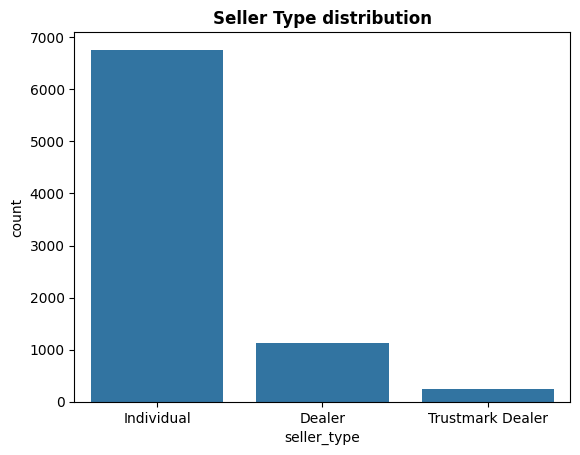

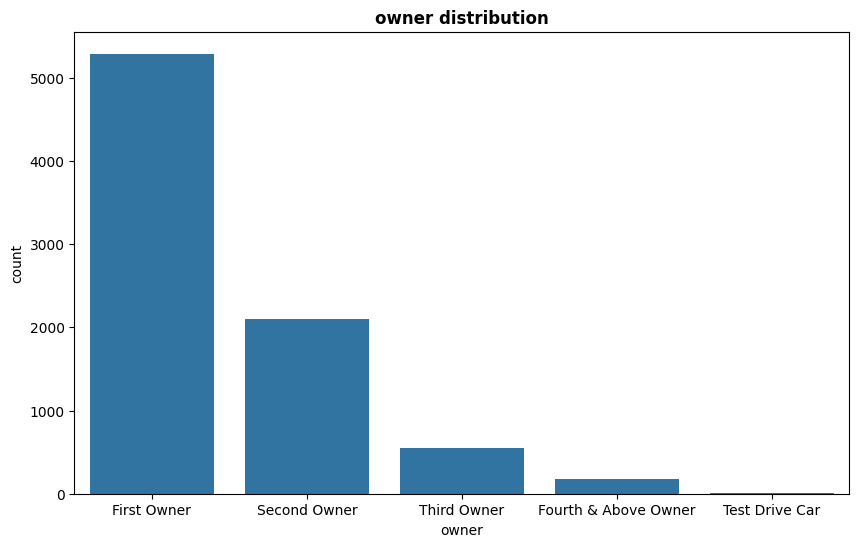

In [27]:
# Create a count plot for seller type.
sns.countplot(data=df,x=df['seller_type'])
plt.title("Seller Type distribution",fontweight='bold')
plt.show()

# Create a count plot for owner category.
plt.figure(figsize=(10,6))
sns.countplot(data=df,x=df['owner'])
plt.title("owner distribution",fontweight='bold')
plt.show()

C:\Users\bogha\AppData\Local\Temp\ipykernel_26712\2073234999.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=df, x='selling_price', kde=True, palette='magma', ax=axs[0])
C:\Users\bogha\AppData\Local\Temp\ipykernel_26712\2073234999.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, y='selling_price', palette='magma')


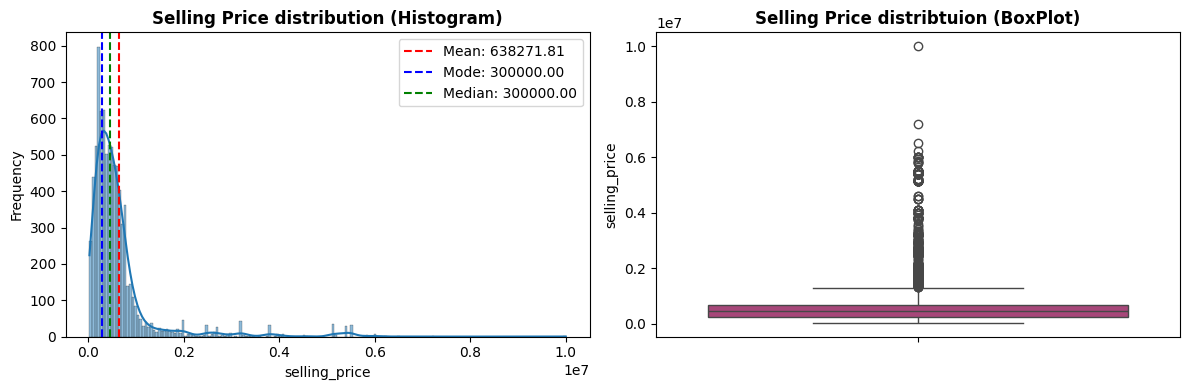

In [28]:
# Create a histogram for selling price.
mean = df['selling_price'].mean()
mode = df['selling_price'].mode()[0]
median = df['selling_price'].median()

fig, axs = plt.subplots(1,2,figsize=(12,4))

sns.histplot(data=df, x='selling_price', kde=True, palette='magma', ax=axs[0])
axs[0].set_title('Selling Price distribution (Histogram)' , fontweight='bold')
axs[0].set_ylabel('Frequency')
axs[0].axvline(mean, color='red', linestyle='--',label=f'Mean: {mean:.2f}')
axs[0].axvline(mode, color='blue', linestyle='--',label=f'Mode: {mode:.2f}')
axs[0].axvline(median, color='green', linestyle='--',label=f'Median: {mode:.2f}')
axs[0].legend()

sns.boxplot(data=df, y='selling_price', palette='magma')
axs[1].set_title('Selling Price distribtuion (BoxPlot)', fontweight='bold')

plt.tight_layout()
plt.show()

C:\Users\bogha\AppData\Local\Temp\ipykernel_26712\1331814956.py:9: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=df, x='km_driven', kde=True, palette='magma', ax=axs[0])
C:\Users\bogha\AppData\Local\Temp\ipykernel_26712\1331814956.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, y='selling_price', palette='magma')


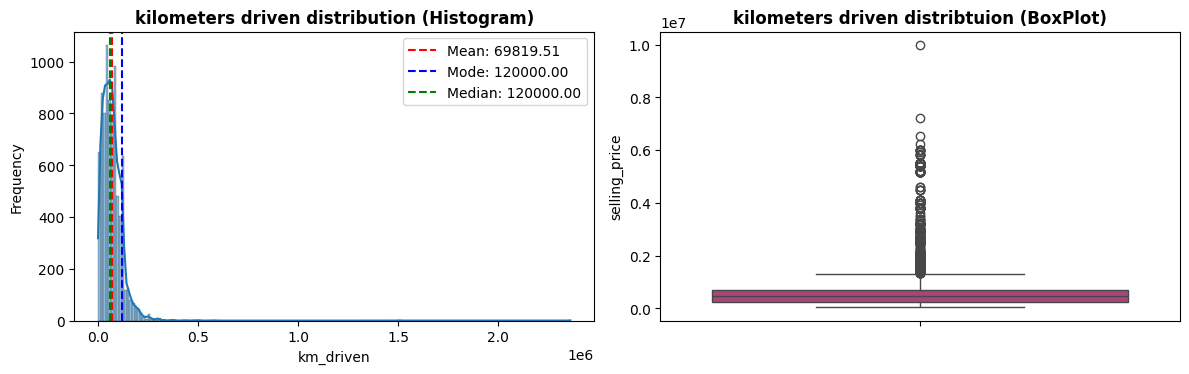

In [29]:
# Create a histogram for kilometers driven.

mean = df['km_driven'].mean()
mode = df['km_driven'].mode()[0]
median = df['km_driven'].median()

fig, axs = plt.subplots(1,2,figsize=(12,4))

sns.histplot(data=df, x='km_driven', kde=True, palette='magma', ax=axs[0])
axs[0].set_title('kilometers driven distribution (Histogram)' , fontweight='bold')
axs[0].set_ylabel('Frequency')
axs[0].axvline(mean, color='red', linestyle='--',label=f'Mean: {mean:.2f}')
axs[0].axvline(mode, color='blue', linestyle='--',label=f'Mode: {mode:.2f}')
axs[0].axvline(median, color='green', linestyle='--',label=f'Median: {mode:.2f}')
axs[0].legend()

sns.boxplot(data=df, y='selling_price', palette='magma')
axs[1].set_title('kilometers driven distribtuion (BoxPlot)', fontweight='bold')

plt.tight_layout()
plt.show()

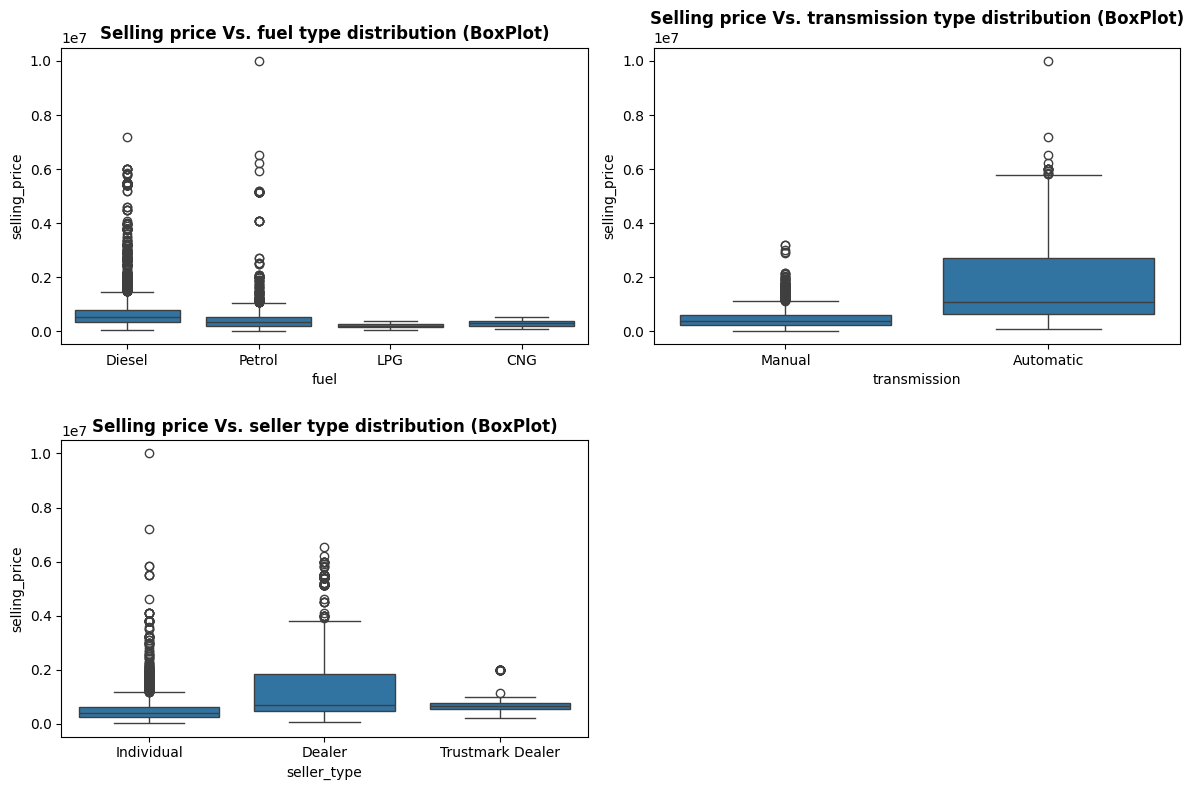

In [30]:
fig, axs = plt.subplots(2,2,figsize=(12,8))

axs = axs.flatten()

# Create a boxplot of selling price by fuel type.
sns.boxplot(data=df,x=df['fuel'],y=df['selling_price'],ax=axs[0])
axs[0].set_title("Selling price Vs. fuel type distribution (BoxPlot)",fontweight='bold')

# Create a boxplot of selling price by transmission type.
sns.boxplot(data=df,x=df['transmission'],y=df['selling_price'],ax=axs[1])
axs[1].set_title("Selling price Vs. transmission type distribution (BoxPlot)",fontweight='bold')

# Create a boxplot of selling price by seller type.
sns.boxplot(data=df,x=df['seller_type'],y=df['selling_price'],ax=axs[2])
axs[2].set_title("Selling price Vs. seller type distribution (BoxPlot)",fontweight='bold')

for i in range(3, len(axs)):
    fig.delaxes(axs[i])

plt.tight_layout()
plt.show()

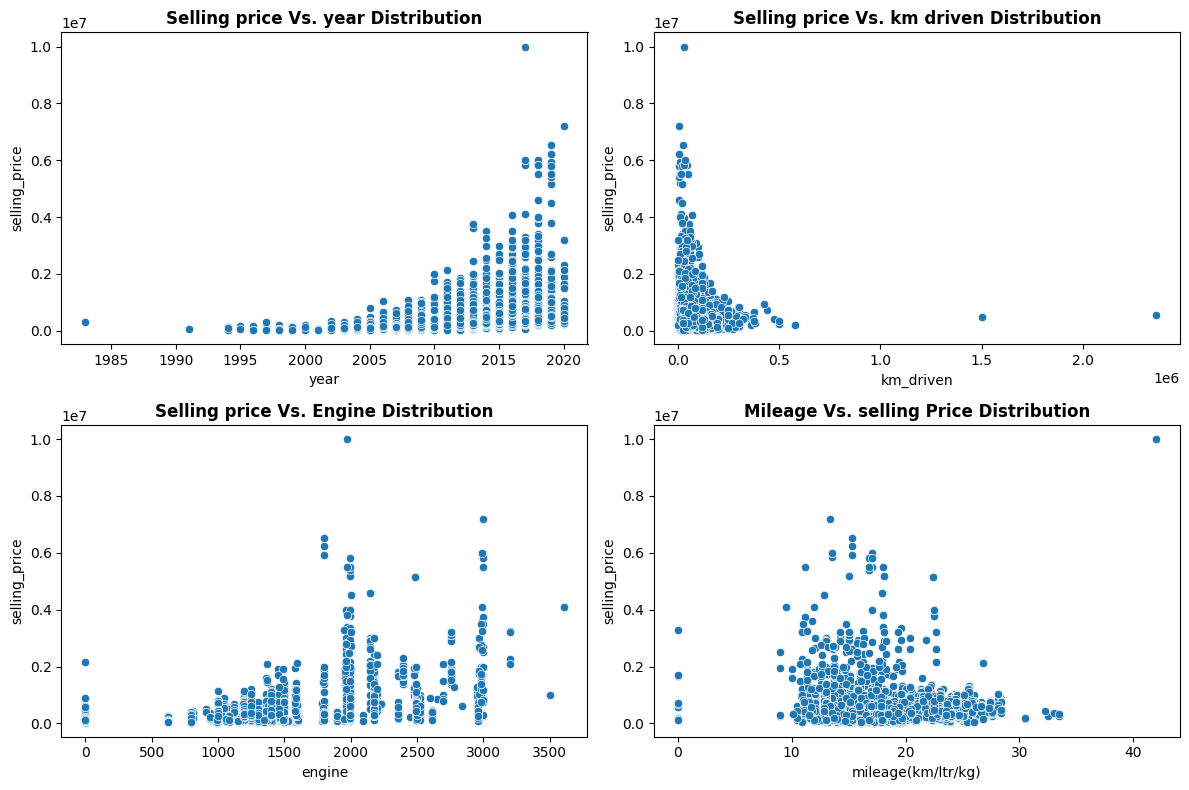

In [31]:

fig, axs = plt.subplots(2,2,figsize=(12,8))

axs = axs.flatten()

# Create a scatter plot of `year` vs `selling_price`.
sns.scatterplot(data=df,x=df['year'],y=df['selling_price'],ax=axs[0])
axs[0].set_title("Selling price Vs. year Distribution",fontweight='bold')

# Create a scatter plot of `km_driven` vs `selling_price`.
sns.scatterplot(data=df,x=df['km_driven'],y=df['selling_price'],ax=axs[1])
axs[1].set_title("Selling price Vs. km driven Distribution",fontweight='bold')

# Create a scatter plot of `engine` vs `selling_price`.
sns.scatterplot(data=df,x=df['engine'],y=df['selling_price'],ax=axs[2])
axs[2].set_title("Selling price Vs. Engine Distribution",fontweight='bold')


sns.scatterplot(data=df, x=df['mileage(km/ltr/kg)'], y=df['selling_price'],ax=axs[3])
axs[3].set_title("Mileage Vs. selling Price Distribution", fontweight='bold')

for i in range(4, len(axs)):
    fig.delaxes(axs[i])

plt.tight_layout()
plt.show()

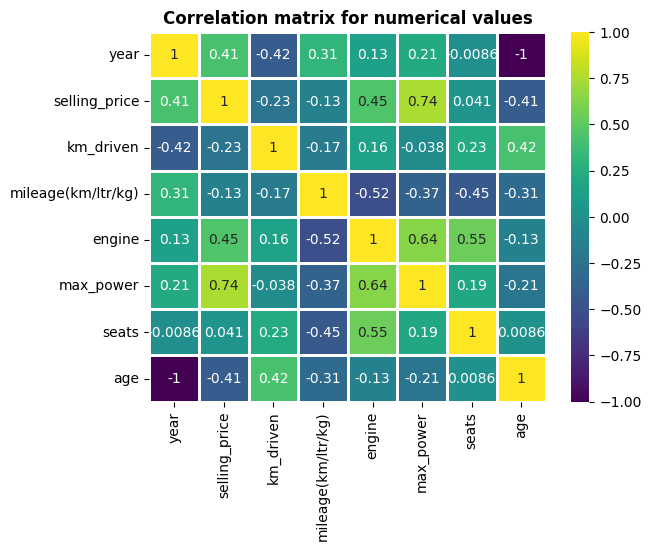

In [32]:
# Create a correlation heatmap.
sns.heatmap(corr_matrix, cmap="viridis", annot=True, linewidths=0.9)
plt.title("Correlation matrix for numerical values",fontweight='bold')
plt.show()

Ordinal Encoding

In [33]:
# Ordinal Encoding for 'seller_type','fuel' and 'transmission' column

seller_type_map = {
    'Dealer':0,
    'Individual':1,
    'Trustmark Dealer':2
}
df['seller_type'] = df['seller_type'].map(seller_type_map)

fuel_map = {
    'CNG':0,
    'Diesel':1,
    'LPG':2,
    'Petrol':3
}

transmission_map = {
    'Manual':0,
    'Automatic':1
}

df['fuel'] = df['fuel'].map(fuel_map)
df['transmission'] = df['transmission'].map(transmission_map)

df.head(5)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,age
0,Maruti Swift Dzire VDI,2014,450000,145500,1,1,0,First Owner,23.40,1248.0,74.00,5.0,12
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,1,1,0,Second Owner,21.14,1498.0,103.52,5.0,12
2,Honda City 2017-2020 EXi,2006,158000,140000,3,1,0,Third Owner,17.70,1497.0,78.00,5.0,20
3,Hyundai i20 Sportz Diesel,2010,225000,127000,1,1,0,First Owner,23.00,1396.0,90.00,5.0,16
4,Maruti Swift VXI BSIII,2007,130000,120000,3,1,0,First Owner,16.10,1298.0,88.20,5.0,19


One-Hot Encoding
Convert categorical variables into numerical format.

Machine learning algorithms cannot work directly with text values.

Examples:

yes → 1

no → 0

In [34]:
# Select all categorical columns
categorical_columns = df.select_dtypes(include=['object']).columns

# Initialize One-Hot Encoder
encoder = OneHotEncoder(sparse_output=False)

encoder_data = encoder.fit_transform(df[categorical_columns])
encoder_df = pd.DataFrame(
    encoder_data,
    columns=encoder.get_feature_names_out(categorical_columns),
    index=df.index
)

# Transform Categorical features
final_df = pd.concat([df.drop(columns=categorical_columns),encoder_df],axis=1)


#### Feature Selection

Separate the dataset into:

- Input Features (X)
- Target Variable (y)

Target Variable:
- price

In [35]:
FEATURE_COLUMNS = final_df.drop(columns='selling_price', axis=1).columns
TARGET_COLUMN = 'selling_price'

#  X & y split
x = final_df[FEATURE_COLUMNS]
y = final_df[TARGET_COLUMN]

# Train & Validation set split
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=0)

print("X Train Shape:",X_train.shape)
print("X Test Shape:",X_test.shape)

X Train Shape: (6502, 2073)
X Test Shape: (1626, 2073)


In [36]:
# XGBRegressor model
model = XGBRegressor()

param_grid = {
    'n_estimator': [50,80,100],
    'learning_rate':[0.01,0.1,0.2],
    'maxdepth':[3,4,5,6,7,8]
}

grid_search = GridSearchCV(estimator=model,param_grid=param_grid,cv=5)
grid_search.fit(x,y)

c:\Users\bogha\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:29:07] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "maxdepth", "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\bogha\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:29:10] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "maxdepth", "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\bogha\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:29:12] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "maxdepth", "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\bogha\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:29:16]

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.1, ...], 'maxdepth': [3, 4, ...], 'n_estimator': [50, 80, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 

In [37]:
# Print out the best parameter & score
print(f'Best score: {grid_search.best_score_}')
print(f'Best hyperparameters: {grid_search.best_params_}')

Best score: 0.9620718002319336
Best hyperparameters: {'learning_rate': 0.2, 'maxdepth': 3, 'n_estimator': 50}


In [44]:
# Train XGBRegressor model
final_model = XGBRegressor(**grid_search.best_params_)

final_model.fit(X_train, y_train)
# y_pred = final_model.predict(X_test)

c:\Users\bogha\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:41:34] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "maxdepth", "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [45]:
# Function to evaluate model performance
def evaluate(name,model,X_test,y_test):
    # Predict on test dataset
    preds = model.predict(X_test)
    
    # Calculate MSE
    mse = mean_squared_error(y_test,preds)
    # Calculate RMSE
    rmse = np.sqrt(mse)
    # Calculate MAE
    mae = mean_absolute_error(y_test,preds)
    # Calculate R² Score
    r2 = r2_score(y_test,preds)
    
    # Print evaluation results
    print(f"  RMSE : {rmse:.2f}")
    print(f"  MSE  : {mse:.2f}")
    print(f"  MAE  : {mae:.2f}")
    print(f"  R2_score : {r2:.2f}")
    
    return preds,y_test

preds,y_testt = evaluate("Car_Price_Preict",final_model,X_test,y_test)

joblib.dump(final_model, "model/car_price_model.pkl")
joblib.dump(FEATURE_COLUMNS, "model/feature_columns.pkl")
joblib.dump("Car_Price_Preict", "model/model_name.pkl")

print("Saved model and feature columns to /model")

  RMSE : 204801.52
  MSE  : 41943662592.00
  MAE  : 81756.43
  R2_score : 0.94
Saved model and feature columns to /model


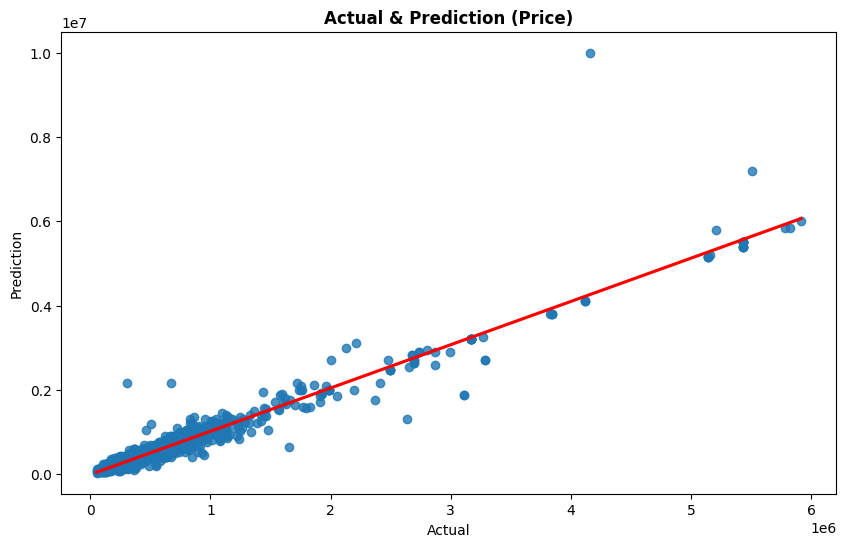

In [56]:
plt.figure(figsize=(10,6))
sns.regplot(x=preds, y=y_testt, ci=None, line_kws={"color": "red"})
plt.title('Actual & Prediction (Price)', fontweight='bold')
plt.xlabel('Actual')
plt.ylabel('Prediction')
plt.show()